In [19]:
import numpy.random as rand
import matplotlib.pyplot as plt

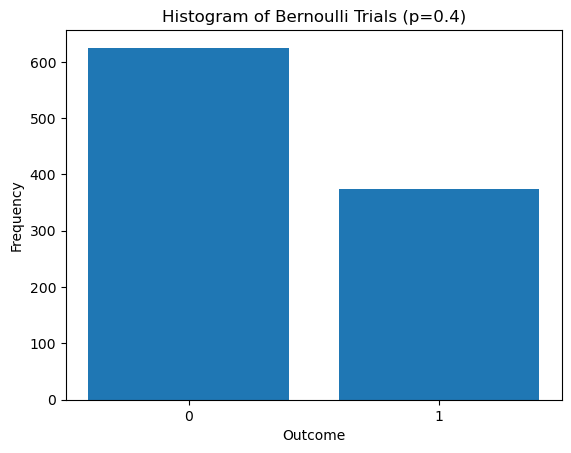

In [ ]:
# a. X ~ Ber(p = 0.4)
#Simulate function
def simulate_bernoulli(p=0.4):
    return 1 if rand.rand() < p else 0

# Run the experiment 1000 times
results = np.array([simulate_bernoulli(p = 0.4) for _ in range(1000)])

# Plot histogram
counts = np.bincount(results)
plt.bar([0, 1], counts, tick_label=['0', '1'])
plt.xlabel('Outcome')
plt.ylabel('Frequency')
plt.title('Histogram of Bernoulli Trials (p=0.4)')
plt.show()

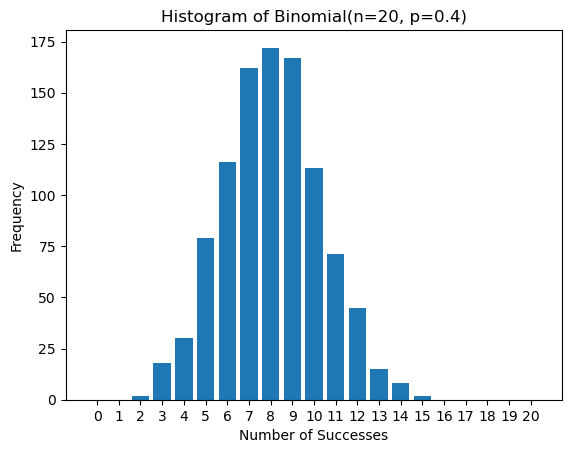

In [ ]:
# b. X ~ Bin(n = 20, p = 0.4)
#Simulate function
def simulate_binomial(n=20, p=0.4):
    results = np.array([simulate_bernoulli(p) for _ in range(n)])
    return np.sum(results)

# Run the experiment 1000 times
results = np.array([simulate_binomial(n=20, p=0.4) for _ in range(1_000)])

# Plot histogram
plt.hist(results, bins=np.arange(-0.5, 21.5, 1), rwidth=0.8)
plt.xlabel('Number of Successes')
plt.ylabel('Frequency')
plt.title('Histogram of Binomial(n=20, p=0.4)')
plt.xticks(np.arange(0, 21, 1))
plt.show()

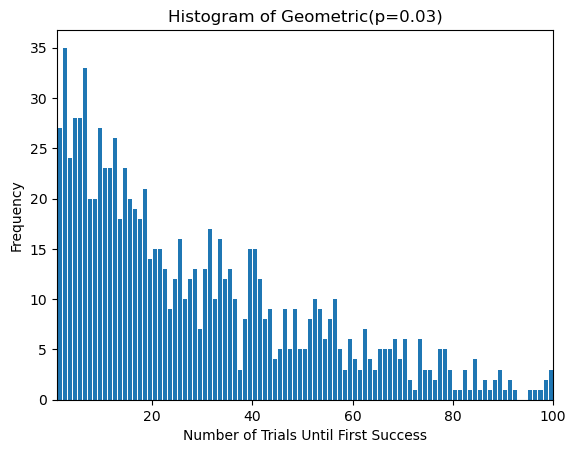

In [52]:
# c. X ~ Geo(p = 0.03)
#Simulate function
def simulate_geometric(p = 0.03):
    num_of_trail = 0
    while simulate_bernoulli(p) == 0:
        num_of_trail += 1
    num_of_trail += 1
    return num_of_trail

# Run the experiment 1000 times
results = np.array([simulate_geometric(p = 0.03) for _ in range(1000)])

# Plot histogram
plt.hist(results, bins=np.arange(1, results.max() + 2), rwidth=0.8)
plt.xlabel('Number of Trials Until First Success')
plt.ylabel('Frequency')
plt.title('Histogram of Geometric(p=0.03)')
plt.xlim(1, 100)
plt.show()

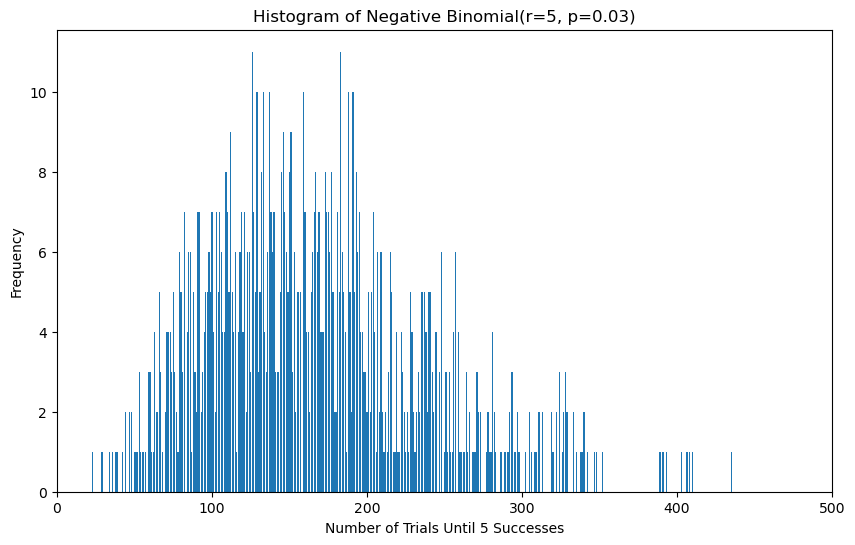

In [58]:
# d. X ~ NegBin(r = 5, p = 0.03)
#Simulate function
def simulate_NegBin(r = 5, p = 0.03):
    num_of_success, num_of_trail = 0, 0
    while num_of_success < r:
        if simulate_bernoulli(p) == 1:
            num_of_success += 1
        num_of_trail += 1
    return num_of_trail

# Run the experiment 1000 times
results = np.array([simulate_NegBin(r = 5, p = 0.03) for _ in range(1000)])

# Plot histogram
plt.figure(figsize=(10,6))
plt.hist(
    results,
    bins=np.arange(results.min()-0.5, results.max()+1.5, 1),
    rwidth=0.8,
)
plt.xlabel('Number of Trials Until 5 Successes')
plt.ylabel('Frequency')
plt.title('Histogram of Negative Binomial(r=5, p=0.03)')
plt.xlim(0, 500)
plt.show()

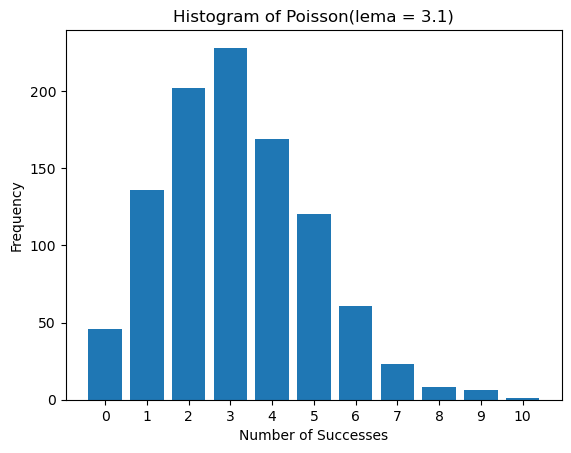

In [64]:
# e. X ~ Poi(\lema = 3.1) approximate
#Simulate function
def simulate_poisson(n = 60_000, lema = 3.1):
    return simulate_binomial(n, p = lema/n)

# Run the experiment 1000 times
results = np.array([simulate_poisson(n = 60_000, lema = 3.1) for _ in range(1_000)])

# Plot histogram
plt.hist(results, bins=np.arange(-0.5, 11.5, 1), rwidth=0.8)
plt.xlabel('Number of Successes')
plt.ylabel('Frequency')
plt.title('Histogram of Poisson(lema = 3.1)')
plt.xticks(np.arange(0, 11, 1))
plt.show()

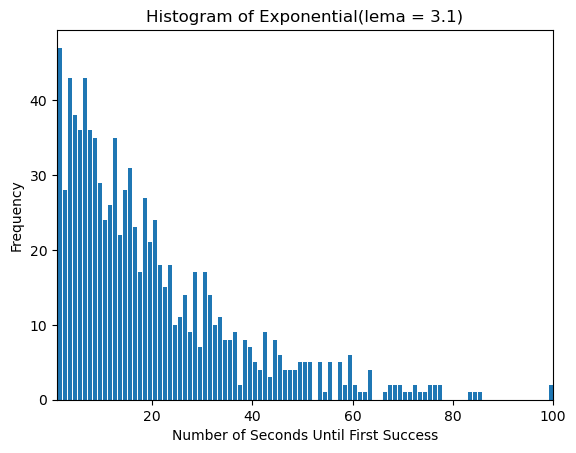

In [71]:
# f. X ~ Exp(\lema = 3.1) approximate
#Simulate function
def simulate_exponential(n = 60_000, lema = 3.1):
    return simulate_geometric(p = lema/n) / 1000 # convert from milliseconds to seconds

# Run the experiment 1000 times
results = np.array([simulate_exponential(n = 60_000, lema = 3.1) for _ in range(1_000)])

# Plot histogram
plt.hist(results, bins=np.arange(1, results.max() + 2), rwidth=0.8)
plt.xlabel('Number of Seconds Until First Success')
plt.ylabel('Frequency')
plt.title('Histogram of Exponential(lema = 3.1)')
plt.xlim(1, 100)
plt.show()